In [1]:

# Buoc 2: Import thu vien

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras import datasets, layers, Model

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices('GPU'))

print("Da import thu vien thanh cong!")


TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Da import thu vien thanh cong!


In [2]:

# Buoc 3: Tai bo du lieu CIFAR-100

(x_train, y_train), (x_test, y_test) = \
    datasets.cifar100.load_data(label_mode='fine')

print("So anh huan luyen:", x_train.shape)
print("So nhan huan luyen:", y_train.shape)

print("So anh kiem tra:", x_test.shape)
print("So nhan kiem tra:", y_test.shape)

print("So lop doi tuong:", len(np.unique(y_train)))


169001437/169001437 ━━━━━━━━━━━━━━━━━━━━ 54s 0us/step
So anh huan luyen: (50000, 32, 32, 3)
So nhan huan luyen: (50000, 1)
So anh kiem tra: (10000, 32, 32, 3)
So nhan kiem tra: (10000, 1)
So lop doi tuong: 100


So lop doi tuong: 100


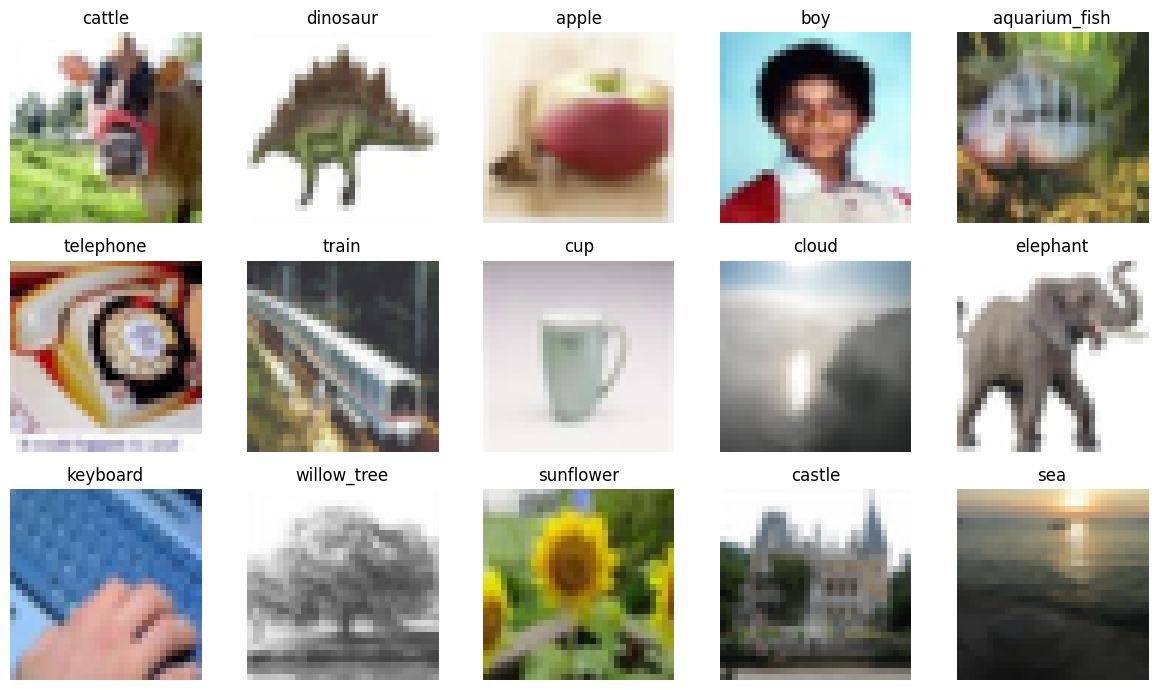

In [4]:

# Buoc 4: Hien thi 15 anh CIFAR-100

class_names = [
    'apple', 'aquarium_fish', 'baby', 'bear',
    'beaver', 'bed', 'bee', 'beetle',
    'bicycle', 'bottle', 'bowl', 'boy',
    'bridge', 'bus', 'butterfly', 'camel',
    'can', 'castle', 'caterpillar', 'cattle',
    'chair', 'chimpanzee', 'clock', 'cloud',
    'cockroach', 'couch', 'crab', 'crocodile',
    'cup', 'dinosaur', 'dolphin', 'elephant',
    'flatfish', 'forest', 'fox', 'girl',
    'hamster', 'house', 'kangaroo', 'keyboard',
    'lamp', 'lawn_mower', 'leopard', 'lion',
    'lizard', 'lobster', 'man', 'maple_tree',
    'motorcycle', 'mountain', 'mouse', 'mushroom',
    'oak_tree', 'orange', 'orchid', 'otter',
    'palm_tree', 'pear', 'pickup_truck',
    'pine_tree', 'plain', 'plate', 'poppy',
    'porcupine', 'possum', 'rabbit', 'raccoon',
    'ray', 'road', 'rocket', 'rose',
    'sea', 'seal', 'shark', 'shrew',
    'skunk', 'skyscraper', 'snail', 'snake',
    'spider', 'squirrel', 'streetcar', 'sunflower',
    'sweet_pepper', 'table', 'tank', 'telephone',
    'television', 'tiger', 'tractor', 'train',
    'trout', 'tulip', 'turtle', 'wardrobe',
    'whale', 'willow_tree', 'wolf', 'woman',
    'worm'
]

print("So lop doi tuong:", len(class_names))

plt.figure(figsize=(12, 7))

for i in range(15):
    plt.subplot(3, 5, i + 1)

    plt.imshow(x_train[i])
    plt.title(class_names[int(y_train[i, 0])])
    plt.axis('off')

plt.tight_layout()
plt.show()


In [11]:

# buoc 5 chuan hoa du lieu CIFAR-100

# Tai lai du lieu goc
(x_train, y_train), (x_test, y_test) = \
    datasets.cifar100.load_data(label_mode='fine')

# Chuan hoa dung 1 lan
x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0

# Kiem tra
print("Pixel min:", x_train.min())
print("Pixel max:", x_train.max())

print("Train:", x_train.shape)
print("Test:", x_test.shape)


Pixel min: 0.0
Pixel max: 1.0
Train: (50000, 32, 32, 3)
Test: (10000, 32, 32, 3)


In [12]:

# Buoc 6: Xay dung mo hinh ResNet CIFAR-100

# Tao Residual Block
def residual_block(x, filters):
    shortcut = x

    # Lop tich chap thu nhat
    x = layers.Conv2D(
        filters, (3, 3),
        padding='same'
    )(x)

    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)

    # Lop tich chap thu hai
    x = layers.Conv2D(
        filters, (3, 3),
        padding='same'
    )(x)

    x = layers.BatchNormalization()(x)

    # Ket noi tat
    x = layers.Add()([x, shortcut])

    x = layers.Activation('relu')(x)

    return x


# Tao dau vao
inputs = layers.Input(shape=(32, 32, 3))

# Lop Conv2D ban dau
x = layers.Conv2D(
    32, (3, 3),
    padding='same',
    activation='relu'
)(inputs)

# Residual Block 1
x = residual_block(x, 32)

# Giam kich thuoc
x = layers.MaxPooling2D((2, 2))(x)

# Residual Block 2
x = residual_block(x, 32)

# Tong hop dac trung
x = layers.GlobalAveragePooling2D()(x)

# Lop phan loai 100 doi tuong
outputs = layers.Dense(
    100, activation='softmax'
)(x)

# Tao mo hinh ResNet
model = Model(inputs, outputs)

# Hien thi cau truc mo hinh
model.summary()


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 32, 32, 3) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 32, 32,    │        896 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 32, 32,    │      9,248 │ conv2d[0][0]      │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 32, 32,    │        128 │ conv2d_1[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 32, 32,    │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 32, 32,    │      9,248 │ activation[0][0]  │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │        128 │ conv2d_2[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 32, 32,    │          0 │ batch_normalizat… │
│                     │ 32)               │            │ conv2d[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_1        │ (None, 32, 32,    │          0 │ add[0][0]         │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 16, 16,    │          0 │ activation_1[0][… │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 16, 16,    │      9,248 │ max_pooling2d[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 16, 16,    │        128 │ conv2d_3[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_2        │ (None, 16, 16,    │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 16, 16,    │      9,248 │ activation_2[0][… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 16, 16,    │        128 │ conv2d_4[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_1 (Add)         │ (None, 16, 16,    │          0 │ batch_normalizat… │
│                     │ 32)               │            │ max_pooling2d[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_3        │ (None, 16, 16,    │          0 │ add_1[0][0]     

 Total params: 41,700 (162.89 KB)

 Trainable params: 41,444 (161.89 KB)

 Non-trainable params: 256 (1.00 KB)

In [13]:

# Buoc 7: Bien dich mo hinh ResNet

model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

print("Bien dich mo hinh ResNet thanh cong!")


Bien dich mo hinh ResNet thanh cong!


In [14]:

# Buoc 8: Huan luyen mang ResNet

history = model.fit(
    x_train,
    y_train,
    epochs=15,
    batch_size=64,
    validation_split=0.2
)

print("Huan luyen ResNet thanh cong!")


Epoch 1/15
625/625 ━━━━━━━━━━━━━━━━━━━━ 23s 16ms/step - accuracy: 0.0838 - loss: 4.0755 - val_accuracy: 0.0902 - val_loss: 3.9736
Epoch 2/15
625/625 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - accuracy: 0.1611 - loss: 3.5238 - val_accuracy: 0.0904 - val_loss: 4.2865
Epoch 3/15
625/625 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - accuracy: 0.2053 - loss: 3.2376 - val_accuracy: 0.1247 - val_loss: 3.7801
Epoch 4/15
625/625 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - accuracy: 0.2429 - loss: 3.0438 - val_accuracy: 0.2121 - val_loss: 3.2424
Epoch 5/15
625/625 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - accuracy: 0.2650 - loss: 2.9044 - val_accuracy: 0.1875 - val_loss: 3.3182
Epoch 6/15
625/625 ━━━━━━━━━━━━━━━━━━━━ 5s 9ms/step - accuracy: 0.2908 - loss: 2.7831 - val_accuracy: 0.2274 - val_loss: 3.1489
Epoch 7/15
625/625 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - accuracy: 0.3068 - loss: 2.6955 - val_accuracy: 0.2316 - val_loss: 3.1949
Epoch 8/15
625/625 ━━━━━━━━━━━━━━━━━━━━ 5s 9ms/step - accuracy: 0.3217 - loss: 2.6126 - val_accuracy: 

In [15]:

# Buoc 9.1: Danh gia ResNet tren CIFAR-100

test_loss, test_acc = model.evaluate(
    x_test,
    y_test,
    verbose=2
)

print("==============================")
print(f"Test Accuracy: {test_acc * 100:.2f}%")
print(f"Test Loss: {test_loss:.4f}")
print("==============================")


313/313 - 3s - 11ms/step - accuracy: 0.2621 - loss: 2.9225
Test Accuracy: 26.21%
Test Loss: 2.9225


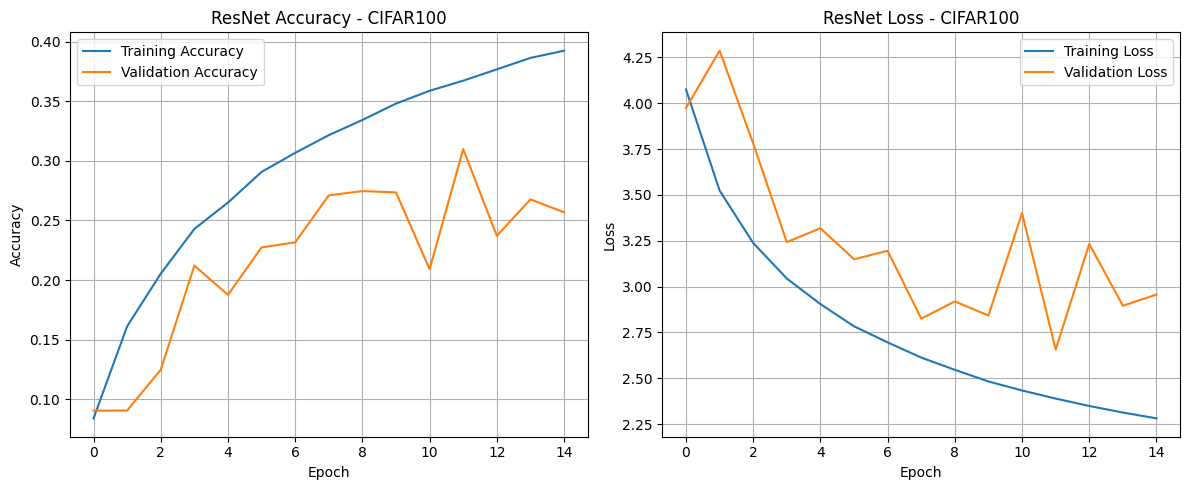

In [16]:

# Buoc 9.2: Ve bieu do ResNet

plt.figure(figsize=(12, 5))

# Bieu do Accuracy
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'],
         label='Training Accuracy')
plt.plot(history.history['val_accuracy'],
         label='Validation Accuracy')

plt.title('ResNet Accuracy - CIFAR100')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

# Bieu do Loss
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'],
         label='Training Loss')
plt.plot(history.history['val_loss'],
         label='Validation Loss')

plt.title('ResNet Loss - CIFAR100')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.savefig('resnet_training.png', dpi=150)
plt.show()


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step


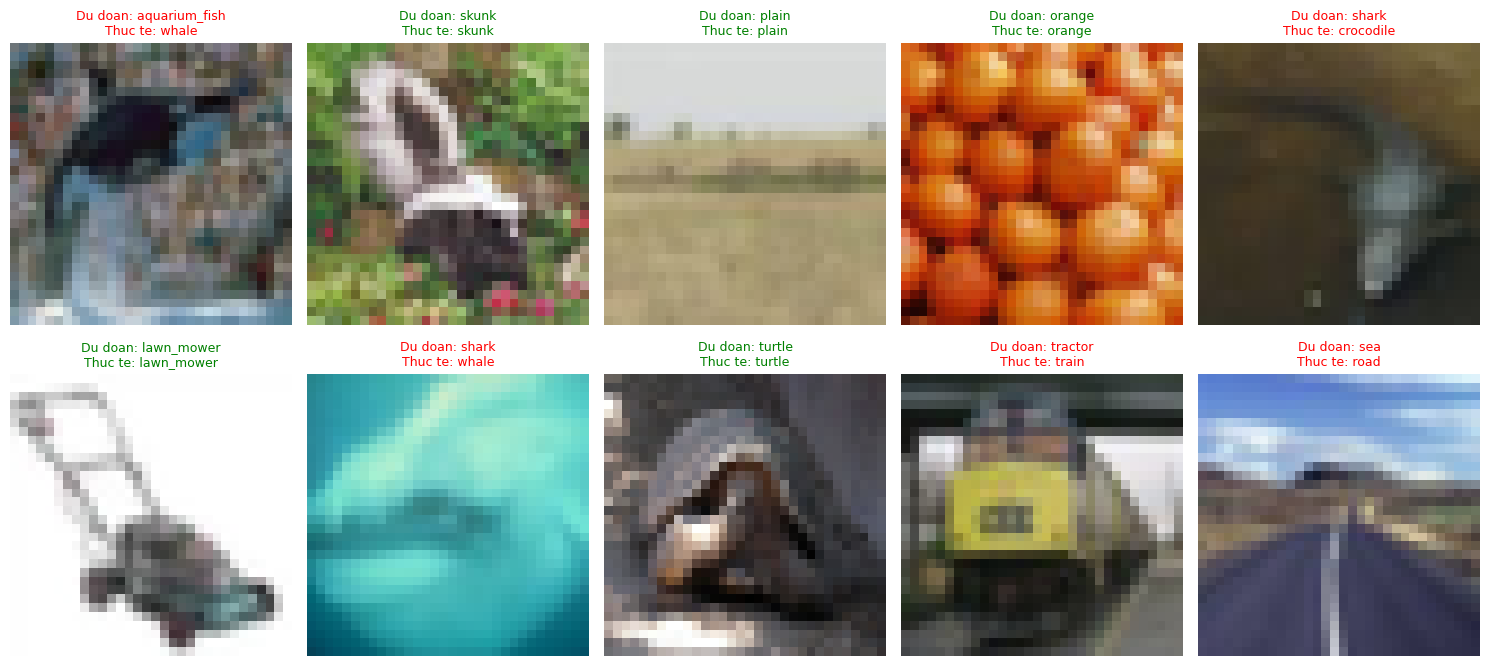

So anh du doan dung: 5/10


In [27]:

# Buoc 9.4: Du doan 10 anh ngau nhien CIFAR-100

# Chon ngau nhien 10 anh khac nhau
indices = np.random.choice(
    len(x_test),
    size=10,
    replace=False
)

# Du doan
predictions = model.predict(x_test[indices])

plt.figure(figsize=(15, 7))

correct = 0

for i in range(10):
    plt.subplot(2, 5, i + 1)

    index = indices[i]

    plt.imshow(x_test[index])

    predicted_label = np.argmax(predictions[i])
    true_label = int(y_test[index, 0])

    if predicted_label == true_label:
        color = 'green'
        correct += 1
    else:
        color = 'red'

    plt.title(
        f"Du doan: {class_names[predicted_label]}\n"
        f"Thuc te: {class_names[true_label]}",
        color=color,
        fontsize=9
    )

    plt.axis('off')

plt.tight_layout()
plt.savefig('resnet_predictions_random.png', dpi=150)
plt.show()

print(f"So anh du doan dung: {correct}/10")


In [29]:

# Luu mo hinh ResNet

model.save('resnet_cifar100_old.keras')

print("Da luu mo hinh ResNet !")


Da luu mo hinh ResNet !
